ANN Binary Classification Results
Training Loss: 0.0682
Test Accuracy: 99.0 %

Sample Predictions:
Actual: 1 | Predicted: 1
Actual: 1 | Predicted: 1
Actual: 1 | Predicted: 0
Actual: 1 | Predicted: 1
Actual: 0 | Predicted: 0
Actual: 1 | Predicted: 1
Actual: 1 | Predicted: 1
Actual: 1 | Predicted: 1
Actual: 1 | Predicted: 1
Actual: 0 | Predicted: 0


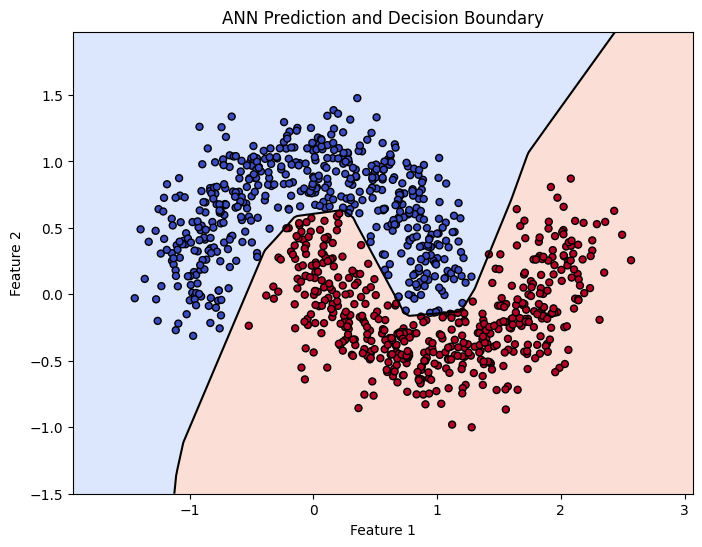

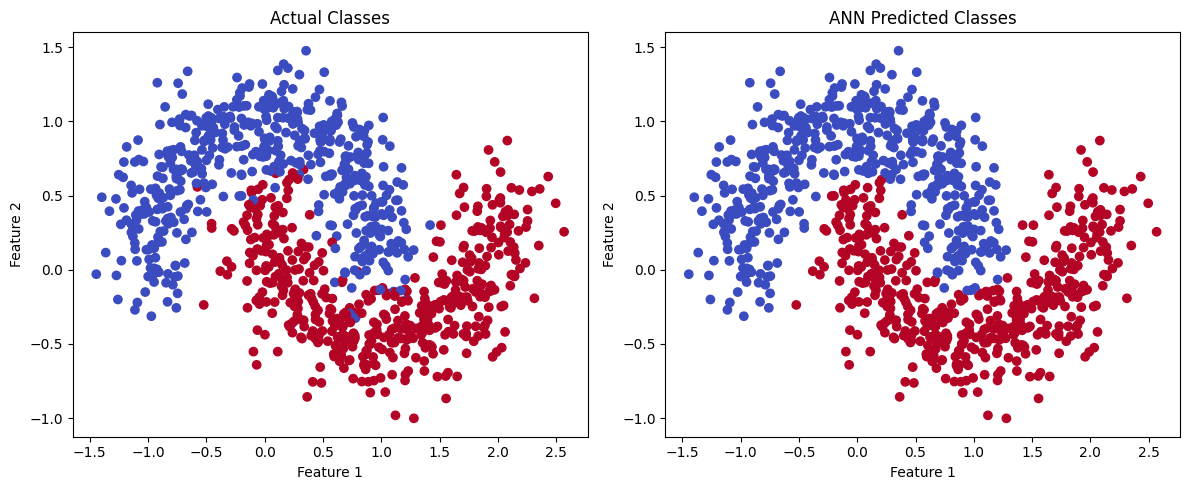

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_test = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)
model = nn.Sequential(
    nn.Linear(2, 16),
    nn.ReLU(),
    nn.Linear(16, 8),
    nn.ReLU(),
    nn.Linear(8, 1),
    nn.Sigmoid()
)
loss_function = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
for epoch in range(200):
    output = model(X_train)
    loss = loss_function(output, y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
with torch.no_grad():
    test_predictions = (model(X_test) >= 0.5).float()
    accuracy = (test_predictions == y_test).float().mean()
print("ANN Binary Classification Results")
print("Training Loss:", round(loss.item(), 4))
print("Test Accuracy:", round(accuracy.item() * 100, 2), "%")
X_all_scaled = scaler.transform(X)
X_all_tensor = torch.tensor(X_all_scaled, dtype=torch.float32)
with torch.no_grad():
    all_predictions = (
        model(X_all_tensor) >= 0.5
    ).int().numpy().flatten()
print("\nSample Predictions:")
for i in range(10):
    print("Actual:", y[i], "| Predicted:", all_predictions[i])
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)
grid = np.c_[xx.ravel(), yy.ravel()]
grid_scaled = scaler.transform(grid)
grid_tensor = torch.tensor(grid_scaled, dtype=torch.float32)
with torch.no_grad():
    probabilities = model(grid_tensor).numpy().reshape(xx.shape)
plt.figure(figsize=(8, 6))
plt.contourf(
    xx, yy, probabilities,
    levels=[0, 0.5, 1], alpha=0.3, cmap="coolwarm"
)
plt.contour(xx, yy, probabilities, levels=[0.5], colors="black")
plt.scatter(
    X[:, 0], X[:, 1],
    c=all_predictions, cmap="coolwarm",
    edgecolors="black", s=25
)
plt.title("ANN Prediction and Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm")
plt.title("Actual Classes")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.subplot(1, 2, 2)
plt.scatter(
    X[:, 0], X[:, 1],
    c=all_predictions, cmap="coolwarm"
)
plt.title("ANN Predicted Classes")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.tight_layout()
plt.show()
